# Predicting a Netflix title's project rating group
## A copy of IE0005.ipynb rewritten in the M1–M5 code style

**Question:** Can genre and description predict the two rating groups used in the
original notebook?

- **Predictors:** `listed_in` (genre) and `description`.
- **Response:** `AdultGroup`, preserving the source notebook's mapping:
  `R`, `TV-MA`, `NC-17` → **18+**; the other accepted ratings → **Not 18+**.
- **Important:** “18+” is a project shorthand for those three labels. Different
  rating systems are not equivalent; in particular, this does not establish an
  official 18-year age threshold for every `R` or `TV-MA` title.

This copy retains the original workflow: quality checks, cleaning, genre tokens,
exploratory plots, train/test split, tuned Naive Bayes, input comparison, learned
tokens and error analysis. It adds an M4 decision-tree comparison, optional M5
investigations, a prediction demonstration and saved outputs.

Keep `netflix_titles.csv` beside this notebook and **Restart Kernel → Run All**.
Outputs are written to `m1_m5_project_outputs/`. The original notebook and CSV are
not edited. A companion presentation is `IE0005_M1_M5_Presentation.pptx`.

## Course-code origins and clearly marked extensions

**COURSE ADAPTATION** means the code follows a supplied notebook's pattern, with
Netflix variables substituted. **PROJECT LOGIC** means newly written Netflix rules
using pandas, NumPy and Python in that style.

| Course file | Patterns used in this copy |
|---|---|
| M1 DataAcquisition | Basic libraries, `pd.read_csv`, DataFrames, `head`, shapes |
| M2 BasicStatistics | `describe`, histogram/boxplot, concatenation |
| M2 ExploratoryAnalysis | `info`, missing values, duplicates, filtering, copies, `re.sub`, category counts, grouped plots |
| M4 ClassificationTree | `train_test_split`, predictor/response tables, `fit`, `predict`, `score`, confusion-matrix heatmaps, prediction/probability tables |
| M5 ClusteringPatterns | Optional KMeans on derived numeric features |
| M5 DetectingAnomalies | Optional LocalOutlierFactor review flags |

No M3 notebook was supplied. Code is organized into short, commented cells using
`np`, `pd`, `sb`, `plt` and explicit model creation/training/prediction steps.

### Outside M1–M5: preserved from the current IE0005.ipynb

- **E1: text encoding — `CountVectorizer`** and genre-token construction.
  [Official API](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html)
- **E2: Naive Bayes — `MultinomialNB`.**
  [Official API](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html)
- **E3: evaluation — `f1_score`, `classification_report`, learned feature log probabilities.**
  [F1](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html),
  [classification report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html)
- **E4: tuning — `make_pipeline` and `GridSearchCV`.** These were already in
  IE0005.ipynb and are retained to tune smoothing by five-fold cross-validation.
  The vectorizer stays inside the pipeline so each fold learns only from its training rows.
  [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html),
  [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

**E5: new support code** uses `Path`, CSV/figure/JSON exports, assertions and version
recording for reproducibility. Project-specific dictionaries, string operations,
loops and the majority baseline are labeled PROJECT LOGIC.

The outside-course portions are marked in their cells. They were adapted from the
user's existing notebook and checked against official API documentation; no external
project solution is used. PowerPoint authoring tools are separate from the analysis.

## 1. Import libraries and acquire the data
**Course basis: M1 and M2.** Use the same basic-library aliases and inspection style.

In [1]:
# Basic Libraries -- M1, M2, M4 and M5
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
import re
sb.set()

# E5: create an output folder and record the run settings
from pathlib import Path
import json
import sys
import sklearn
import matplotlib
output_folder = Path("m1_m5_project_outputs")
output_folder.mkdir(exist_ok = True)
random_seed = 42
class_order = ["Not 18+", "18+"]

# Read the CSV file -- M1
netflixdata = pd.read_csv("netflix_titles.csv")
print("Data type :", type(netflixdata))
print("Data dims :", netflixdata.shape)
netflixdata.head()

Data type : <class 'pandas.DataFrame'>
Data dims : (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 2. Check the variables and data quality
**Course basis: M2 ExploratoryAnalysis.**

In [2]:
# Information about the Variables -- M2
netflixdata.info()
print("\nMissing values per column")
print(netflixdata.isnull().sum())
print("\nDuplicate rows :", netflixdata.duplicated().sum())
print("Duplicate descriptions :", netflixdata["description"].duplicated().sum())

# PROJECT LOGIC: describe the three variables needed for this project
variable_info = pd.DataFrame({
    "Variable" : ["listed_in", "description", "rating"],
    "Meaning" : ["One or more genre labels", "Short text synopsis", "Recorded audience rating"],
    "Type" : ["Categorical, multiple labels", "Text", "Categorical"],
    "Role" : ["Predictor", "Predictor", "Source of the response"]
})
variable_info

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB

Missing values per column
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dt

,Variable,Meaning,Type,Role
0,listed_in,One or more genre labels,"Categorical, multiple labels",Predictor
1,description,Short text synopsis,Text,Predictor
2,rating,Recorded audience rating,Categorical,Source of the response


Number of Recorded Ratings : 17
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NaN            4
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64


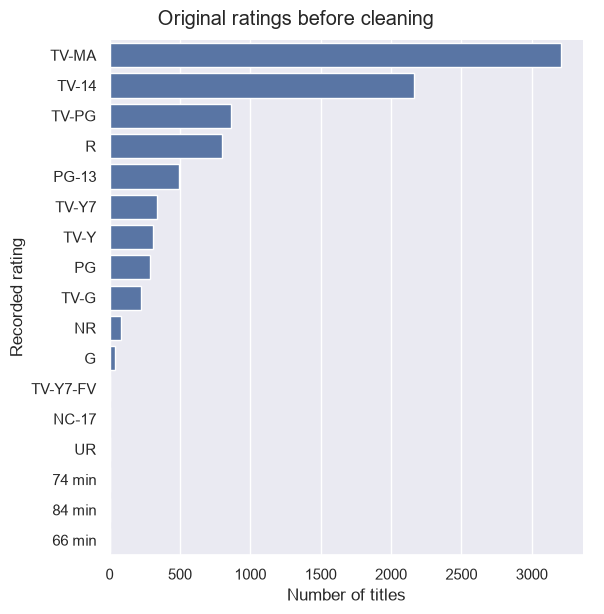

In [3]:
# Categories of Rating in the Dataset -- M2
print("Number of Recorded Ratings :", len(netflixdata["rating"].dropna().unique()))
print(netflixdata["rating"].value_counts(dropna = False))
g = sb.catplot(y = "rating", data = netflixdata, kind = "count",
               order = netflixdata["rating"].value_counts().index, height = 6)
g.set_axis_labels("Number of titles", "Recorded rating")
g.fig.suptitle("Original ratings before cleaning", y = 1.02)
# E5: save a figure
g.fig.savefig(output_folder / "01_original_ratings.png", dpi = 150, bbox_inches = "tight")
plt.show()

## 3. Clean the data and create the response

The following cell preserves the data-cleaning code from `IE0005.ipynb`
verbatim: keep valid ratings, drop missing descriptions/genres and remove exact
duplicate descriptions, keeping the first. No additional text normalization or
cleaning rules are applied.

The next cell only prepares names, derived features and audit exports for the
remaining analysis. The original CSV is unchanged.

In [4]:
# Valid Age Ratings
valid_ratings = ["TV-Y", "TV-Y7", "TV-Y7-FV", "TV-G", "G", "PG", "TV-PG",
                 "PG-13", "TV-14", "R", "TV-MA", "NC-17"]

# Keep only the usable Titles
netflixclean = netflixdata[netflixdata["rating"].isin(valid_ratings)]
netflixclean = netflixclean.dropna(subset = ["description", "listed_in"])
netflixclean = netflixclean.drop_duplicates(subset = "description")

# Check the sample sizes
print("Before Cleaning :", netflixdata.shape)
print("After Cleaning  :", netflixclean.shape)

Before Cleaning : (8807, 12)
After Cleaning  : (8686, 12)


In [5]:
# Prepare the original cleaned data for the remaining analysis
# E5 / PROJECT LOGIC: column names, derived features and audit exports only
netflix_clean = netflixclean[
    ["show_id", "title", "listed_in", "description", "rating"]].copy()
netflix_clean.rename(columns = {
    "show_id" : "ShowID", "title" : "Title", "listed_in" : "Genre",
    "description" : "Description", "rating" : "Rating"
}, inplace = True)
netflix_clean["AdultGroup"] = netflix_clean["Rating"].isin(
    ["R", "TV-MA", "NC-17"]).map({True : "18+", False : "Not 18+"})
netflix_clean["DescriptionKey"] = netflix_clean["Description"]
netflix_clean["WordCount"] = netflix_clean["Description"].str.split().str.len()
netflix_clean["CharacterCount"] = netflix_clean["Description"].str.len()
netflix_clean["GenreCount"] = netflix_clean["Genre"].str.split(",").str.len()

# Audit the rows removed by the original cleaning cell
eligible = netflixdata[netflixdata["rating"].isin(valid_ratings)].dropna(
    subset = ["description", "listed_in"]).copy()
eligible["AdultGroup"] = eligible["rating"].isin(
    ["R", "TV-MA", "NC-17"]).map({True : "18+", False : "Not 18+"})
conflicting_descriptions = eligible.groupby("description")["AdultGroup"].nunique()
exclusion_reason = pd.Series("", index = netflixdata.index, dtype = "object")
exclusion_reason.loc[netflixdata["rating"].isnull()] = "Missing rating"
exclusion_reason.loc[netflixdata["rating"].isin(["NR", "UR"])] = "Unrated label"
exclusion_reason.loc[(exclusion_reason == "") &
    ~netflixdata["rating"].isin(valid_ratings)] = "Unexpected rating"
exclusion_reason.loc[(exclusion_reason == "") &
    netflixdata[["description", "listed_in"]].isnull().any(axis = 1)] = "Missing predictor"
exclusion_reason.loc[(exclusion_reason == "") &
    ~netflixdata.index.isin(netflixclean.index)] = "Repeated description (keep first)"
excluded_data = netflixdata.loc[~netflixdata.index.isin(netflixclean.index)].copy()
excluded_data["ExclusionReason"] = exclusion_reason.loc[excluded_data.index]
print("Excluded rows by reason")
print(excluded_data["ExclusionReason"].value_counts())
print("\nResponse distribution")
print(netflix_clean["AdultGroup"].value_counts())

assert netflix_clean.index.equals(netflixclean.index)
assert netflix_clean["Description"].equals(netflixclean["description"].rename("Description"))
assert netflix_clean["DescriptionKey"].is_unique
assert len(netflix_clean) + len(excluded_data) == len(netflixdata)
netflix_clean.to_csv(output_folder / "netflix_clean.csv", index = False)
excluded_data.to_csv(output_folder / "excluded_rows.csv", index = False)
netflix_clean.head()

Excluded rows by reason
ExclusionReason
Unrated label                        83
Repeated description (keep first)    31
Missing rating                        4
Unexpected rating                     3
Name: count, dtype: int64

Response distribution
AdultGroup
Not 18+    4682
18+        4004
Name: count, dtype: int64


,ShowID,Title,Genre,Description,Rating,AdultGroup,DescriptionKey,WordCount,CharacterCount,GenreCount
0,s1,Dick Johnson Is Dead,Documentaries,"As her father nears the end of his life, filmm...",PG-13,Not 18+,"As her father nears the end of his life, filmm...",27,152,1
1,s2,Blood & Water,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",TV-MA,18+,"After crossing paths at a party, a Cape Town t...",27,147,3
2,s3,Ganglands,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,TV-MA,18+,To protect his family from a powerful drug lor...,27,146,3
3,s4,Jailbirds New Orleans,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",TV-MA,18+,"Feuds, flirtations and toilet talk go down amo...",24,147,2
4,s5,Kota Factory,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,TV-MA,18+,In a city of coaching centers known to train I...,24,152,3


## 4. Prepare the text predictor

**E1 / PROJECT LOGIC: retained from IE0005.ipynb, outside M1–M5.**
Each genre is converted to a prefixed token: `International Movies` becomes
`g_International_Movies`. The prefix separates genre labels from ordinary synopsis
words. This cell creates strings only; vocabulary learning happens inside each
training pipeline.

In [6]:
# PROJECT LOGIC: preserve complete genre labels as separate tokens
netflix_clean["GenreTokens"] = netflix_clean["Genre"].str.split(",").apply(
    lambda items: " ".join(
        "g_" + item.strip().replace(" ", "_").replace("'", "").replace("-", "_").replace("&", "and")
        for item in items if item.strip()
    )
)
netflix_clean["Text"] = netflix_clean["Description"] + " " + netflix_clean["GenreTokens"]
print("Original Genre :", netflix_clean["Genre"].iloc[0])
print("Combined Text :", netflix_clean["Text"].iloc[0])

Original Genre : Documentaries
Combined Text : As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to help them both face the inevitable. g_Documentaries


## 5. Split the predictors and response

**Course basis: M4.** The original notebook uses a stratified 80/20 split with seed
42; retain it here. Move it before detailed exploration so those plots can use
training rows. Exact descriptions are unique after the documented
deduplication step and cannot cross the split. Near-duplicate titles can still remain.

In [7]:
# Extract Response and Predictors -- M4
from sklearn.model_selection import train_test_split
X = pd.DataFrame(netflix_clean[["Text"]])
y = pd.DataFrame(netflix_clean["AdultGroup"])

# Split the Dataset into Train and Test -- M4, with original notebook settings
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.20, random_state = random_seed, stratify = y["AdultGroup"])
train_data = netflix_clean.loc[X_train.index].copy()
test_data = netflix_clean.loc[X_test.index].copy()

print("Train Set :", y_train.shape, X_train.shape)
print("Test Set :", y_test.shape, X_test.shape)
split_summary = pd.DataFrame({
    "Train" : y_train["AdultGroup"].value_counts(),
    "Test" : y_test["AdultGroup"].value_counts()
}).reindex(class_order)

# E5: verify separation and export assignments
assert set(train_data["DescriptionKey"]).isdisjoint(test_data["DescriptionKey"])
assert len(train_data) + len(test_data) == len(netflix_clean)
assert (split_summary > 0).all().all()
split_assignment = pd.concat([
    train_data[["ShowID"]].assign(Split = "Train"),
    test_data[["ShowID"]].assign(Split = "Test")
])
split_assignment.to_csv(output_folder / "split_assignments.csv", index = False)
split_summary.to_csv(output_folder / "split_summary.csv")
split_summary

Train Set : (6948, 1) (6948, 1)
Test Set : (1738, 1) (1738, 1)


,Train,Test
AdultGroup,,
Not 18+,3745,937
18+,3203,801


## 6. Explore relevant training-data patterns
### 6.1 Original ratings and target groups
**Course basis: M2 category plots.**

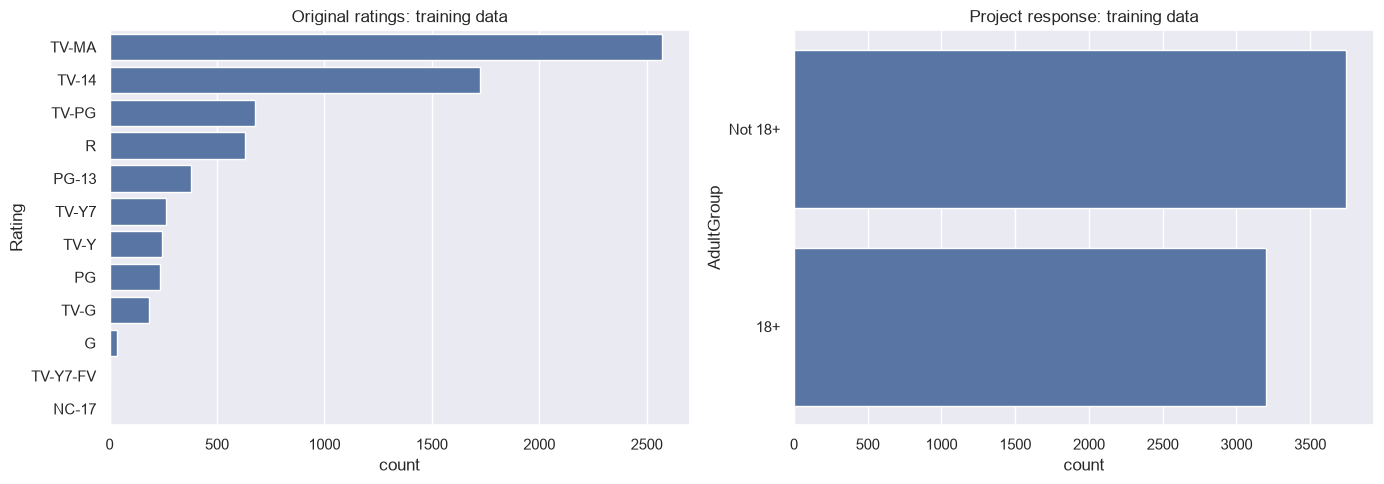

Training majority group : Not 18+
Training majority share : 0.539


In [8]:
# Count Plot for the Response -- M2 and M4
f, axes = plt.subplots(1, 2, figsize = (14, 5))
sb.countplot(y = "Rating", data = train_data,
             order = train_data["Rating"].value_counts().index, ax = axes[0])
sb.countplot(y = "AdultGroup", data = train_data, order = class_order, ax = axes[1])
axes[0].set_title("Original ratings: training data")
axes[1].set_title("Project response: training data")
plt.tight_layout()
plt.savefig(output_folder / "02_training_groups.png", dpi = 150)
plt.show()

# PROJECT LOGIC: define the majority baseline from training labels only
majority_class = y_train["AdultGroup"].value_counts().index[0]
print("Training majority group :", majority_class)
print("Training majority share :", round((y_train["AdultGroup"] == majority_class).mean(), 3))

### 6.2 Description length
**Course basis: M2 statistics, histogram and boxplot.**

         WordCount
count  6948.000000
mean     23.900691
std       2.824798
min      10.000000
25%      22.000000
50%      24.000000
75%      26.000000
max      48.000000

Average words by group
AdultGroup
18+        23.9
Not 18+    23.9
Name: WordCount, dtype: float64


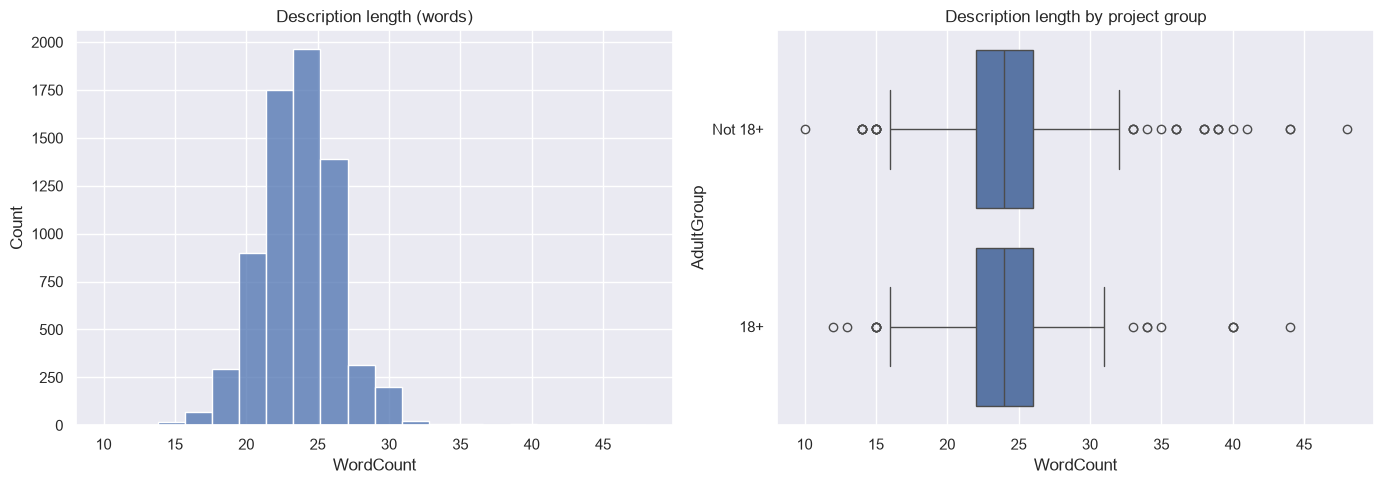

In [9]:
# Summary Statistics for Description Length -- M2
description_length = pd.DataFrame(train_data["WordCount"])
print(description_length.describe())
print("\nAverage words by group")
print(train_data.groupby("AdultGroup")["WordCount"].mean().round(1))

f, axes = plt.subplots(1, 2, figsize = (14, 5))
sb.histplot(data = train_data, x = "WordCount", bins = 20, ax = axes[0])
sb.boxplot(x = "WordCount", y = "AdultGroup", data = train_data,
           order = class_order, orient = "h", ax = axes[1])
axes[0].set_title("Description length (words)")
axes[1].set_title("Description length by project group")
plt.tight_layout()
plt.savefig(output_folder / "03_description_length.png", dpi = 150)
plt.show()

### 6.3 Common description words
**E1: preserved from the original notebook.** These exploratory vectorizers use only
training rows and are separate from the classifier pipelines.

In [10]:
# E1: convert training descriptions into word counts
from sklearn.feature_extraction.text import CountVectorizer

for group in class_order:
    word_counter = CountVectorizer(stop_words = "english")
    word_counts = word_counter.fit_transform(
        train_data.loc[train_data["AdultGroup"] == group, "Description"])
    word_totals = np.asarray(word_counts.sum(axis = 0)).ravel()
    top_words = pd.Series(word_totals,
        index = word_counter.get_feature_names_out()).sort_values(ascending = False).head(15)
    print("\nMost common words for", group)
    print(top_words)


Most common words for Not 18+
life           354
new            328
young          327
world          292
family         272
love           234
friends        216
man            209
woman          200
series         180
school         172
father         153
help           149
documentary    147
finds          146
dtype: int64

Most common words for 18+
life           315
young          264
new            235
family         231
man            216
woman          196
world          169
love           143
friends        138
series         137
documentary    127
takes          121
group          120
special        111
years          110
dtype: int64


### 6.4 Genre and the project “18+” label
**Course basis: M2 grouping and category plots.** **PROJECT LOGIC:** split genres
and calculate the fraction labeled 18+ within each genre. Include only genres with
at least 100 training titles, retaining the source notebook's support threshold.
Each title can contribute to more than one genre.

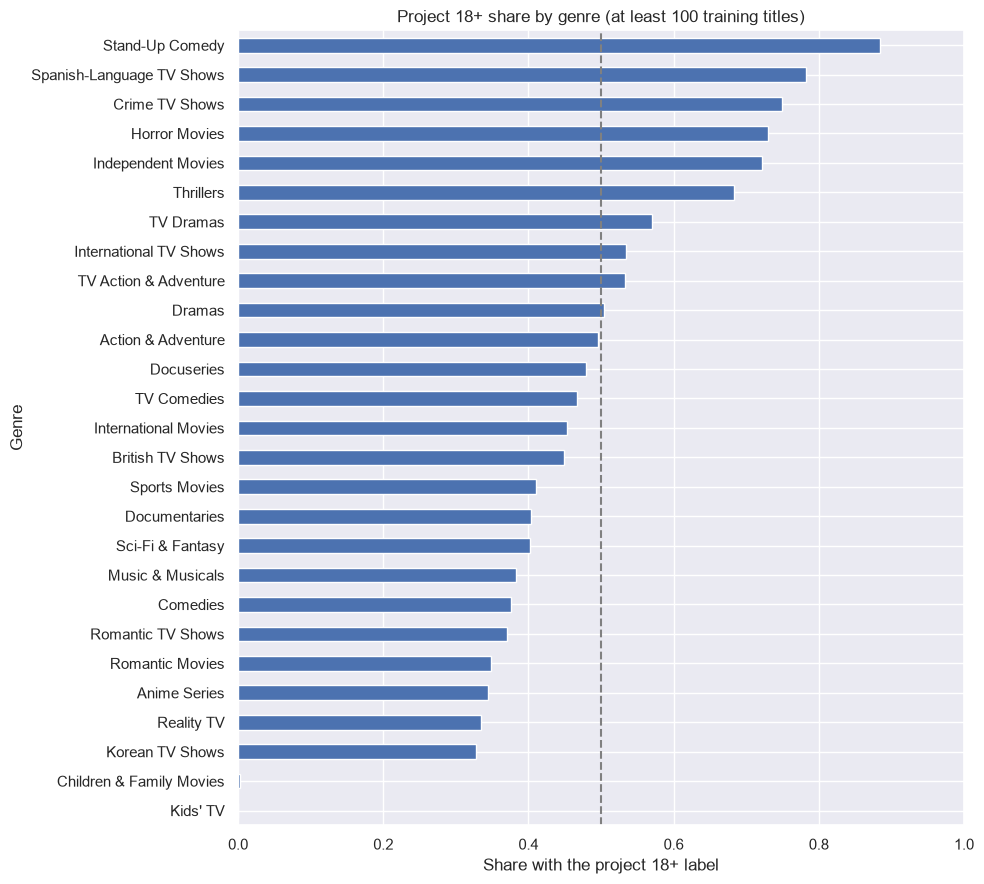

,TitleCount,AdultShare
Genre,,
Kids' TV,363,0.000
Children & Family Movies,505,0.002
Korean TV Shows,125,0.328
Reality TV,203,0.335
Anime Series,145,0.345
Romantic Movies,493,0.349
Romantic TV Shows,294,0.371
Comedies,1334,0.376
Music & Musicals,300,0.383


In [11]:
# PROJECT LOGIC: expand the genre labels and group the training data
genre_data = train_data[["Genre", "AdultGroup"]].copy()
genre_data["Genre"] = genre_data["Genre"].str.split(", ")
genre_data = genre_data.explode("Genre", ignore_index = True)
genre_data["AdultIndicator"] = genre_data["AdultGroup"] == "18+"

# M2 groupby pattern: count titles and calculate the share for each genre
genre_share = pd.DataFrame({
    "TitleCount" : genre_data.groupby("Genre").size(),
    "AdultShare" : genre_data.groupby("Genre")["AdultIndicator"].mean()
})
genre_share = genre_share[genre_share["TitleCount"] >= 100].sort_values("AdultShare")
genre_share["AdultShare"].plot.barh(figsize = (10, 9))
plt.axvline(0.5, color = "grey", linestyle = "--")
plt.xlabel("Share with the project 18+ label")
plt.title("Project 18+ share by genre (at least 100 training titles)")
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig(output_folder / "04_genre_share.png", dpi = 150)
plt.show()
genre_share.to_csv(output_folder / "training_genre_share.csv")
genre_share.round(3)

**Interpretation:** the genre proportions and common words suggest possible
associations with the target. They do not prove causation. Description length alone
may overlap between groups, so the model uses the words themselves. The majority
baseline makes it possible to judge whether the model improves on a simple guess.

## 7. Create and train Multinomial Naive Bayes

**M4 style:** create → fit → predict → evaluate.
**E1, E2 and E4:** word counts, Naive Bayes, a pipeline and five-fold tuning were
already in the source notebook but are not taught in the supplied M1–M5 files.

Retain the original alpha candidates `[0.1, 0.5, 1, 2]`. Select alpha using training
cross-validation macro F1. The pipeline learns vocabulary separately inside each
fold and then refits the chosen configuration on all training rows.
The reserved test set is never used to choose alpha.

In [12]:
# E1 / E2 / E4: imports retained from the source IE0005 notebook
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score, classification_report

# Create the Naive Bayes model -- M4 creation style, E1/E2 model classes
combined_model = make_pipeline(
    CountVectorizer(token_pattern = r"(?u)\b\w+\b"),
    MultinomialNB()
)

# E4: tune smoothing using the training data only
combined_search = GridSearchCV(
    combined_model,
    {"multinomialnb__alpha" : [0.1, 0.5, 1, 2]},
    scoring = "f1_macro", cv = 5
)

# Train the model -- M4 fit style
combined_search.fit(X_train["Text"], y_train["AdultGroup"])
print("Best alpha :", combined_search.best_params_)
print("Training CV Macro F1 :", round(combined_search.best_score_, 4))

Best alpha : {'multinomialnb__alpha': 1}
Training CV Macro F1 : 0.6953


## 8. Compare description, genre and combined inputs

**Original experiment retained:** the same train/test indices, estimator, alpha
candidates and cross-validation score are used for each input variant. Model/input
selection uses training CV scores. Test predictions are made after all three searches
finish. The combined model remains the main model for direct comparison with the
source notebook; its results are not presented as necessarily best.

In [13]:
# E1 / E2 / E4: create and train the description-only model
description_model = make_pipeline(
    CountVectorizer(token_pattern = r"(?u)\b\w+\b"),
    MultinomialNB()
)
description_search = GridSearchCV(
    description_model, {"multinomialnb__alpha" : [0.1, 0.5, 1, 2]},
    scoring = "f1_macro", cv = 5)
description_search.fit(train_data["Description"], y_train["AdultGroup"])

# E1 / E2 / E4: create and train the genre-only model
genre_model = make_pipeline(
    CountVectorizer(token_pattern = r"(?u)\b\w+\b"),
    MultinomialNB()
)
genre_search = GridSearchCV(
    genre_model, {"multinomialnb__alpha" : [0.1, 0.5, 1, 2]},
    scoring = "f1_macro", cv = 5)
genre_search.fit(train_data["GenreTokens"], y_train["AdultGroup"])

cv_results = pd.DataFrame({
    "Model" : ["Naive Bayes: description", "Naive Bayes: genre", "Naive Bayes: both"],
    "CV Macro F1" : [description_search.best_score_, genre_search.best_score_, combined_search.best_score_],
    "Best alpha" : [description_search.best_params_["multinomialnb__alpha"],
                    genre_search.best_params_["multinomialnb__alpha"],
                    combined_search.best_params_["multinomialnb__alpha"]]
}).set_index("Model")
selected_nb = cv_results["CV Macro F1"].idxmax()
print("Naive Bayes input selected from training CV :", selected_nb)
cv_results.to_csv(output_folder / "training_cv_results.csv")
cv_results.round(4)

Naive Bayes input selected from training CV : Naive Bayes: both


,CV Macro F1,Best alpha
Model,,
Naive Bayes: description,0.6649,0.5
Naive Bayes: genre,0.6720,0.5
Naive Bayes: both,0.6953,1.0


## 9. Add an M4 decision-tree comparison

**Course basis: M4 ClassificationTree.** Fit a tree with maximum depth 4, as in the
course's multiclass example, using the same combined training vocabulary. No test
rows are used to fit the word counter. The tree is a fixed course reference, not a
test-tuned replacement. The word-count matrix is kept sparse to avoid allocating
a large dense table; this storage format is part of E1.

In [14]:
# Extract the fitted text features -- E1
combined_counter = combined_search.best_estimator_.named_steps["countvectorizer"]
X_tree_train = combined_counter.transform(X_train["Text"])
X_tree_test = combined_counter.transform(X_test["Text"])

# Import Decision Tree Classifier -- M4
from sklearn.tree import DecisionTreeClassifier
dectree = DecisionTreeClassifier(max_depth = 4, random_state = random_seed)

# Train the Decision Tree Classifier -- M4
dectree.fit(X_tree_train, y_train["AdultGroup"])
print("Decision Tree Training Accuracy :", dectree.score(X_tree_train, y_train["AdultGroup"]))

Decision Tree Training Accuracy : 0.6073690270581462


## 10. Evaluate the frozen models on the test set

**Course basis: M4 predictions, accuracy and confusion-matrix heatmaps.**
**E3:** macro F1 and classification reports supplement accuracy.
The baseline predicts the most common **training** label, fixing the source
notebook's test-majority calculation.

In [15]:
# Predict Response corresponding to Test Predictors -- M4
combined_train_pred = combined_search.predict(X_train["Text"])
combined_test_pred = combined_search.predict(X_test["Text"])
description_test_pred = description_search.predict(test_data["Description"])
genre_test_pred = genre_search.predict(test_data["GenreTokens"])
tree_test_pred = dectree.predict(X_tree_test)
baseline_test_pred = np.repeat(majority_class, len(y_test))

# Check the Goodness of Fit -- M4
print("Goodness of Fit of Combined Naive Bayes\tTrain Dataset")
print("Classification Accuracy :", combined_search.score(X_train["Text"], y_train["AdultGroup"]))
print("\nGoodness of Fit of Combined Naive Bayes\tTest Dataset")
print("Classification Accuracy :", combined_search.score(X_test["Text"], y_test["AdultGroup"]))
print("Macro F1 :", f1_score(y_test["AdultGroup"], combined_test_pred, average = "macro"))
print("\nClassification report -- E3")
print(classification_report(y_test["AdultGroup"], combined_test_pred,
                            labels = class_order, digits = 3, zero_division = 0))

Goodness of Fit of Combined Naive Bayes	Train Dataset


Classification Accuracy : 0.9101526445541142

Goodness of Fit of Combined Naive Bayes	Test Dataset
Classification Accuracy : 0.7072167606597379
Macro F1 : 0.7072167606597379

Classification report -- E3
              precision    recall  f1-score   support

     Not 18+      0.737     0.713     0.725       937
         18+      0.677     0.703     0.690       801

    accuracy                          0.708      1738
   macro avg      0.707     0.708     0.707      1738
weighted avg      0.709     0.708     0.709      1738



                          Accuracy  Macro F1
Model                                       
Majority baseline           0.5391    0.3503
Decision tree: both         0.6162    0.5370
Naive Bayes: description    0.6674    0.6664
Naive Bayes: genre          0.6870    0.6767
Naive Bayes: both           0.7083    0.7072


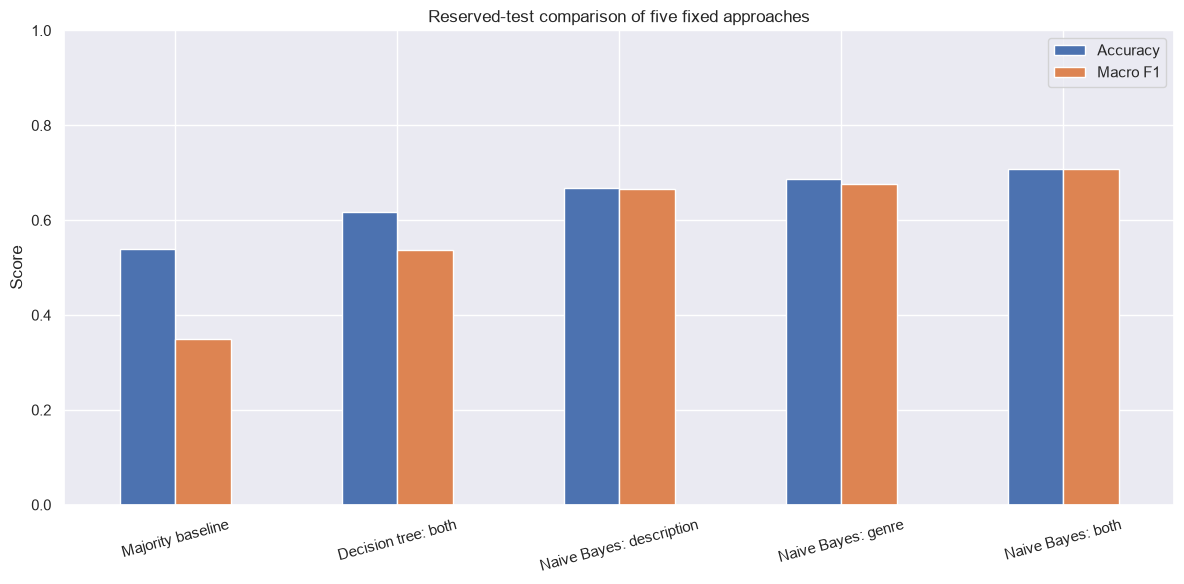

In [16]:
# PROJECT LOGIC: summarize all fixed approaches; E3: Macro F1
test_predictions = {
    "Majority baseline" : baseline_test_pred,
    "Decision tree: both" : tree_test_pred,
    "Naive Bayes: description" : description_test_pred,
    "Naive Bayes: genre" : genre_test_pred,
    "Naive Bayes: both" : combined_test_pred
}
result_rows = []
for name in test_predictions:
    prediction = test_predictions[name]
    result_rows.append({
        "Model" : name,
        "Accuracy" : np.mean(prediction == y_test["AdultGroup"]),
        "Macro F1" : f1_score(y_test["AdultGroup"], prediction,
                             labels = class_order, average = "macro", zero_division = 0)
    })
comparison = pd.DataFrame(result_rows).set_index("Model")
comparison.to_csv(output_folder / "test_results.csv")
print(comparison.round(4))

# M2: compare model results with a bar chart
comparison.plot.bar(figsize = (12, 6), ylim = (0, 1), rot = 15)
plt.title("Reserved-test comparison of five fixed approaches")
plt.ylabel("Score")
plt.xlabel("")
plt.tight_layout()
plt.savefig(output_folder / "05_model_comparison.png", dpi = 150)
plt.show()

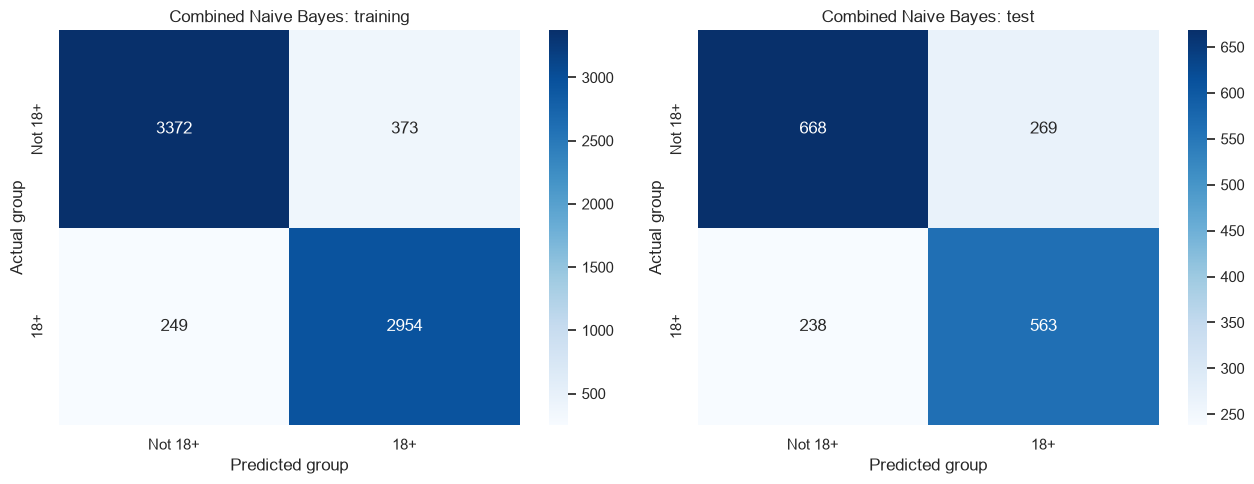

In [17]:
# Plot the Confusion Matrices for Train and Test -- M4
from sklearn.metrics import confusion_matrix
train_matrix = confusion_matrix(y_train["AdultGroup"], combined_train_pred, labels = class_order)
test_matrix = confusion_matrix(y_test["AdultGroup"], combined_test_pred, labels = class_order)
f, axes = plt.subplots(1, 2, figsize = (13, 5))
sb.heatmap(train_matrix, annot = True, fmt = ".0f", cmap = "Blues",
           xticklabels = class_order, yticklabels = class_order, ax = axes[0])
sb.heatmap(test_matrix, annot = True, fmt = ".0f", cmap = "Blues",
           xticklabels = class_order, yticklabels = class_order, ax = axes[1])
axes[0].set_title("Combined Naive Bayes: training")
axes[1].set_title("Combined Naive Bayes: test")
for ax in axes:
    ax.set_xlabel("Predicted group")
    ax.set_ylabel("Actual group")
plt.tight_layout()
plt.savefig(output_folder / "06_confusion_matrices.png", dpi = 150)
plt.show()

## 11. Examine what Naive Bayes learned

**E3: retained from the source notebook.** Compare token log probabilities between
the two classes. Positive values associate the token with the project 18+ class;
negative values associate it with Not 18+. These associations are not explanations
of official ratings and are not causal effects.

In [18]:
# E1 / E3: inspect fitted token probabilities
naive_bayes = combined_search.best_estimator_.named_steps["multinomialnb"]
tokens = np.array(combined_counter.get_feature_names_out())
adult_index = list(naive_bayes.classes_).index("18+")
other_index = list(naive_bayes.classes_).index("Not 18+")
log_difference = naive_bayes.feature_log_prob_[adult_index] - naive_bayes.feature_log_prob_[other_index]
is_genre = np.array([token.startswith("g_") for token in tokens])

for label, mask in [("Genres", is_genre), ("Description words", ~is_genre)]:
    token_table = pd.DataFrame({
        "Token" : tokens[mask], "LogDifference" : log_difference[mask]
    }).sort_values("LogDifference")
    print("\n" + label + " associated with Not 18+")
    print(token_table.head(10).to_string(index = False))
    print("\n" + label + " associated with 18+")
    print(token_table.tail(10).sort_values("LogDifference", ascending = False).to_string(index = False))


Genres associated with Not 18+
                       Token  LogDifference
                   g_kids_tv      -5.765465
g_children_and_family_movies      -5.399723
    g_faith_and_spirituality      -2.170897
     g_science_and_nature_tv      -1.397707
            g_anime_features      -0.966924
     g_tv_sci_fi_and_fantasy      -0.894164
                    g_movies      -0.737349
             g_teen_tv_shows      -0.586151
           g_korean_tv_shows      -0.573293
                  g_tv_shows      -0.561459

Genres associated with 18+
                           Token  LogDifference
               g_stand_up_comedy       2.134013
     g_spanish_language_tv_shows       1.384451
                g_crime_tv_shows       1.216166
                 g_horror_movies       1.118827
                     g_tv_horror       1.112518
            g_independent_movies       1.080182
                  g_lgbtq_movies       1.039947
                  g_tv_thrillers       0.914448
                     g_t

## 12. Inspect errors by original rating
**Course basis: M2 groupby and M4 actual/predicted tables.**

In [19]:
# Summarize Actuals and Predictions -- M4
results = test_data[["ShowID", "Title", "Rating", "Genre", "Description"]].copy()
results["ActualGroup"] = y_test["AdultGroup"]
results["PredictedGroup"] = combined_test_pred
results["Correct"] = results["ActualGroup"] == results["PredictedGroup"]

# M2: group results by original rating, including the support count
rating_accuracy = pd.DataFrame({
    "Accuracy" : results.groupby("Rating")["Correct"].mean(),
    "TestTitles" : results.groupby("Rating").size()
}).sort_values("Accuracy")
print(rating_accuracy.round(3))
print("\nSmall rating groups have less reliable accuracy estimates.")
results.to_csv(output_folder / "test_predictions.csv", index = False)
rating_accuracy.to_csv(output_folder / "accuracy_by_original_rating.csv")
results[results["Correct"] == False].head(10)

          Accuracy  TestTitles
Rating                        
NC-17        0.500           2
TV-14        0.577         416
PG-13        0.602         108
TV-MA        0.693         632
R            0.743         167
TV-PG        0.755         184
PG           0.941          51
TV-G         0.944          36
G            1.000           5
TV-Y         1.000          63
TV-Y7        1.000          71
TV-Y7-FV     1.000           3

Small rating groups have less reliable accuracy estimates.


,ShowID,Title,Rating,Genre,Description,ActualGroup,PredictedGroup,Correct
6819,s6820,Gabriel and the Mountain,TV-MA,"Dramas, Independent Movies, International Movies","In a drama based on a true story, Brazilian ba...",18+,Not 18+,False
3132,s3133,Dil Dhadakne Do,TV-MA,"Comedies, Dramas, International Movies",While hosting a shipboard holiday for relative...,18+,Not 18+,False
6554,s6555,Dagh Ujala,TV-MA,"Dramas, Independent Movies, International Movies",A lesbian daughter fights off an arranged marr...,18+,Not 18+,False
5933,s5934,The Borgias,TV-MA,TV Dramas,Follow the lives of the notorious Borgia famil...,18+,Not 18+,False
6145,s6146,American Masters: Ted Williams,TV-MA,"Documentaries, Sports Movies",Baseball legend Ted Williams fights to become ...,18+,Not 18+,False
5439,s5440,My Only Love Song,TV-MA,"International TV Shows, Korean TV Shows, Roman...",When things don't go her way during a shooting...,18+,Not 18+,False
4000,s4001,5 Flights Up,PG-13,"Comedies, Dramas, Independent Movies","A couple finds unexpected drama when, after 40...",Not 18+,18+,False
4908,s4909,Goodnight DJ 1,TV-14,"International TV Shows, TV Dramas, TV Horror",Young radio announcers from varying background...,Not 18+,18+,False
175,s176,The Blue Lagoon,R,"Dramas, Romantic Movies","Two shipwrecked children, stranded for years o...",18+,Not 18+,False
8485,s8486,The Right One,TV-14,"Dramas, International Movies, Romantic Movies","Under pressure to marry, a rich playboy is con...",Not 18+,18+,False


## 13. Optional M5 exploration

Use KMeans and LocalOutlierFactor on **training-only** word count, character count
and genre count. Standardize using training means and standard deviations, a new
pandas arithmetic adaptation of M2 statistics.

These clusters describe synopsis format, not age groups. A 5% anomaly assumption is
not evidence that 5% of the data is wrong. Flags are retained for review; no rows are
removed and these features do not enter the main classifier.

         WordCount  CharacterCount  GenreCount
Cluster                                       
0            20.46          128.75        2.28
1            24.48          146.16        1.58
2            24.87          146.81        3.00


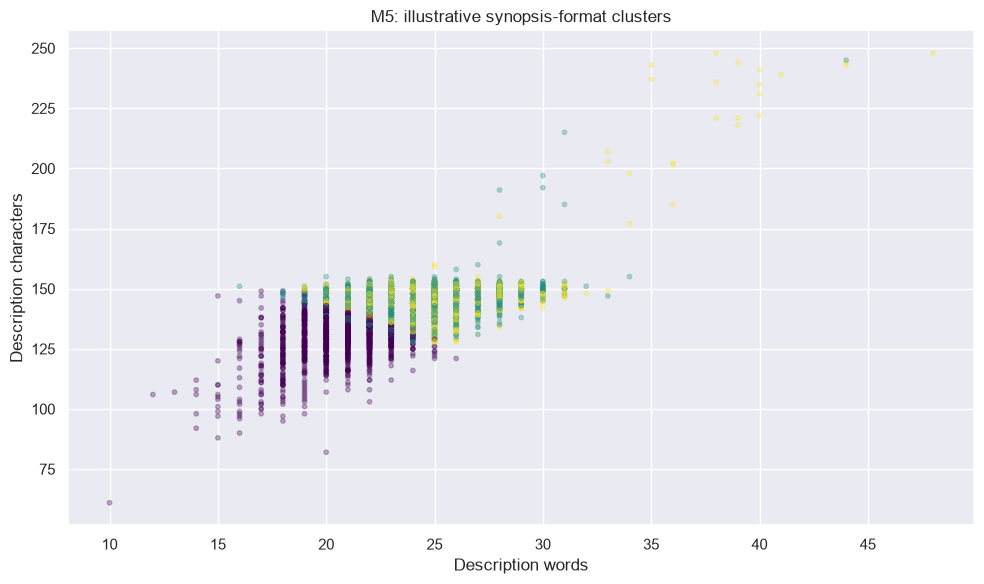

In [20]:
# Extract numeric Features -- M5
format_data = pd.DataFrame(train_data[["WordCount", "CharacterCount", "GenreCount"]])
format_scaled = (format_data - format_data.mean()) / format_data.std()

# Create and fit KMeans -- M5
from sklearn.cluster import KMeans
num_clust = 3
kmeans = KMeans(n_clusters = num_clust, n_init = 10, random_state = random_seed)
kmeans.fit(format_scaled)
cluster_labels = kmeans.predict(format_scaled)
format_labeled = format_data.copy()
format_labeled["Cluster"] = pd.Categorical(cluster_labels)
print(format_labeled.groupby("Cluster", observed = True).mean().round(2))

f = plt.figure(figsize = (10, 6))
plt.scatter(x = "WordCount", y = "CharacterCount", c = cluster_labels,
            data = format_labeled, cmap = "viridis", alpha = 0.3, s = 10)
plt.xlabel("Description words")
plt.ylabel("Description characters")
plt.title("M5: illustrative synopsis-format clusters")
plt.tight_layout()
plt.savefig(output_folder / "07_format_clusters.png", dpi = 150)
plt.show()

In [21]:
# Import and fit LocalOutlierFactor -- M5
from sklearn.neighbors import LocalOutlierFactor

# PROJECT LOGIC: avoid neighborhoods consisting only of identical measurements
largest_repeat = format_data.groupby(["WordCount", "CharacterCount", "GenreCount"]).size().max()
num_neighbors = max(20, int(largest_repeat) + 1)
cont_fraction = 0.05
lof = LocalOutlierFactor(n_neighbors = num_neighbors, contamination = cont_fraction)
anomaly_labels = lof.fit_predict(format_scaled)
anomaly_review = train_data[["ShowID", "Title", "WordCount", "CharacterCount", "GenreCount"]].copy()
anomaly_review["Anomaly"] = anomaly_labels
print("Neighbors used :", num_neighbors)
print("Rows flagged for review :", (anomaly_labels == -1).sum())
print("Rows removed by M5 :", 0)
anomaly_review.to_csv(output_folder / "training_anomaly_review.csv", index = False)
anomaly_review[anomaly_review["Anomaly"] == -1].head(10)

Neighbors used : 53
Rows flagged for review : 337
Rows removed by M5 : 0


,ShowID,Title,WordCount,CharacterCount,GenreCount,Anomaly
1860,s1861,The Cabin with Bert Kreischer,27,152,2,-1
2629,s2630,Bheeshma,28,152,3,-1
401,s402,Sky Rojo,25,124,3,-1
6548,s6549,Dad,28,169,1,-1
910,s911,Monster,22,153,1,-1
3458,s3459,Living Undocumented,13,107,1,-1
1604,s1605,Ari Eldjárn: Pardon My Icelandic,23,153,1,-1
2198,s2199,The Hater,25,152,3,-1
8391,s8392,The Legend of Michael Mishra,28,134,3,-1
248,s249,The Chair,26,153,2,-1


## 14. Project demonstration

**Course basis: M4 prediction tables and probabilities.** First inspect held-out
examples with known labels. Then edit the invented examples below and run their
cell. The demonstration uses the combined Naive Bayes model from the source workflow.

The true labels of invented examples are unknown. Displayed probabilities are
uncalibrated model scores and should not be interpreted as a guarantee.

In [22]:
# M4: display actual and predicted labels for held-out examples
demo_examples = results.groupby("ActualGroup", sort = False).head(3)
demo_examples[["Title", "Rating", "ActualGroup", "PredictedGroup", "Correct"]]

,Title,Rating,ActualGroup,PredictedGroup,Correct
1676,Hawaizaada,TV-14,Not 18+,Not 18+,True
889,The Woman in the Window,R,18+,18+,True
2791,Self Made: Inspired by the Life of Madam C.J. ...,TV-MA,18+,18+,True
1527,Morphle,TV-Y,Not 18+,Not 18+,True
6500,Closed Circuit,R,18+,18+,True
8339,The Healer,TV-14,Not 18+,Not 18+,True


In [23]:
# PROJECT LOGIC: edit these inputs during the demonstration
demo_data = pd.DataFrame({
    "Title" : ["Forest Friends", "The Missing Witness", "Second Chance"],
    "Genre" : ["Kids' TV", "Crime TV Shows, TV Dramas", "Dramas, Romantic Movies"],
    "Description" : [
        "Friendly animals learn to share and solve small problems together.",
        "A detective investigates a violent crime and uncovers secrets in a dangerous city.",
        "Two old friends meet again and discover an unexpected chance at love."
    ]
})
demo_data["GenreTokens"] = demo_data["Genre"].str.split(",").apply(
    lambda items: " ".join(
        "g_" + item.strip().replace(" ", "_").replace("'", "").replace("-", "_").replace("&", "and")
        for item in items if item.strip()
    )
)
demo_data["Text"] = demo_data["Description"] + " " + demo_data["GenreTokens"]

# M4: predict response and probabilities; E1/E2: fitted text model
demo_prediction = combined_search.predict(demo_data["Text"])
demo_probability = combined_search.predict_proba(demo_data["Text"])
demo_result = demo_data[["Title", "Genre", "Description"]].copy()
demo_result["PredictedGroup"] = demo_prediction
demo_result["UncalibratedModelScore"] = demo_probability.max(axis = 1).round(3)
demo_result["KnownTokenCount"] = np.asarray(
    combined_counter.transform(demo_data["Text"]).sum(axis = 1)).ravel()
print("If KnownTokenCount is zero, the input is outside the learned vocabulary.")
demo_result.to_csv(output_folder / "demo_predictions.csv", index = False)
demo_result

If KnownTokenCount is zero, the input is outside the learned vocabulary.


,Title,Genre,Description,PredictedGroup,UncalibratedModelScore,KnownTokenCount
0,Forest Friends,Kids' TV,Friendly animals learn to share and solve smal...,Not 18+,1.000,11
1,The Missing Witness,"Crime TV Shows, TV Dramas",A detective investigates a violent crime and u...,18+,0.998,15
2,Second Chance,"Dramas, Romantic Movies",Two old friends meet again and discover an une...,Not 18+,0.939,14


## 15. Findings and limits

Read the CV table before the test table: the best input by training CV is reported
without choosing on the test set. Compare the combined model to the majority
baseline and the two single-input variants. A difference on one split does not
establish that one input is always superior.

The target is a project-defined binary proxy, not a precise official age threshold.
Keeping the first repeated description follows the original notebook but can
discard legitimate variants; use the exclusion log to review that decision.
Related titles and near-duplicate synopses may still be shared across splits.
Short synopses may omit content relevant to a rating. Word counts ignore word order,
and the Naive Bayes conditional-independence assumption is approximate.

The dataset and label conventions may not represent future Netflix titles. Results
are measured on a fixed split, with no claim of statistical significance.

In [24]:
# PROJECT LOGIC: report actual findings from this run
print("Research question: can genre and description predict the project rating group?")
print("Naive Bayes input selected by training CV :", selected_nb)
print("Combined Naive Bayes test accuracy :", round(comparison.loc["Naive Bayes: both", "Accuracy"], 4))
print("Combined Naive Bayes test Macro F1 :", round(comparison.loc["Naive Bayes: both", "Macro F1"], 4))
print("Majority baseline test accuracy :", round(comparison.loc["Majority baseline", "Accuracy"], 4))
print("Combined minus description-only Macro F1 :",
      round(comparison.loc["Naive Bayes: both", "Macro F1"] -
            comparison.loc["Naive Bayes: description", "Macro F1"], 4))
print("Combined minus genre-only Macro F1 :",
      round(comparison.loc["Naive Bayes: both", "Macro F1"] -
            comparison.loc["Naive Bayes: genre", "Macro F1"], 4))

Research question: can genre and description predict the project rating group?
Naive Bayes input selected by training CV : Naive Bayes: both
Combined Naive Bayes test accuracy : 0.7083
Combined Naive Bayes test Macro F1 : 0.7072
Majority baseline test accuracy : 0.5391
Combined minus description-only Macro F1 : 0.0408
Combined minus genre-only Macro F1 : 0.0305


## 16. Presentation and submission

Use the companion `IE0005_M1_M5_Presentation.pptx` and the saved figures. Suggested
eight-minute flow: question (45 s), preparation (60 s), training-data patterns
(75 s), models and cross-validation (75 s), results/errors (105 s), demonstration
(60 s), limitations/extensions/contributions (60 s).

Before presenting, run the notebook and keep the saved demo output available.
State which work each team member actually performed; no names or contributions
have been invented. Check the course brief and assemble the code, data, slides and
references into the required ZIP. Team review, rehearsal and submission remain
human tasks.

**References:** supplied M1/M2/M4/M5 notebooks; the original `IE0005.ipynb`;
[project README](https://github.com/kyvenlim72-lang/IE1005-Mini-Project);
[dataset](https://www.kaggle.com/datasets/shivamb/netflix-shows/data);
official API links in the extension table. All external additions are marked E1–E5.

In [25]:
# E5: save environment details and the exact evidence used for slides
requirements = {
    "numpy" : np.__version__, "pandas" : pd.__version__,
    "matplotlib" : matplotlib.__version__, "seaborn" : sb.__version__,
    "scikit-learn" : sklearn.__version__
}
with open(output_folder / "analysis_requirements.txt", "w", encoding = "utf-8") as file:
    for package in requirements:
        file.write(package + "==" + requirements[package] + "\n")
presentation_data = {
    "raw_rows" : len(netflixdata), "clean_rows" : len(netflix_clean),
    "excluded_counts" : excluded_data["ExclusionReason"].value_counts().to_dict(),
    "group_counts" : netflix_clean["AdultGroup"].value_counts().to_dict(),
    "train_rows" : len(train_data), "test_rows" : len(test_data),
    "selected_nb" : selected_nb,
    "cv_results" : cv_results.reset_index().to_dict(orient = "records"),
    "test_results" : comparison.reset_index().to_dict(orient = "records"),
    "confusion_matrix" : test_matrix.tolist(), "class_order" : class_order,
    "classification_report" : classification_report(y_test["AdultGroup"], combined_test_pred,
        labels = class_order, output_dict = True, zero_division = 0),
    "genre_share" : genre_share.reset_index().to_dict(orient = "records"),
    "demo_predictions" : demo_result[["Title", "PredictedGroup"]].to_dict(orient = "records"),
    "tokens" : len(tokens),
    "conflicting_description_groups" : int((conflicting_descriptions > 1).sum())
}
with open(output_folder / "presentation_data.json", "w", encoding = "utf-8") as file:
    json.dump(presentation_data, file, indent = 2)
print("Saved results in", output_folder)

Saved results in m1_m5_project_outputs
